# IMM - Taller No 3 Grupo 01





-----
##Periodo de un pendulo (física)
-----

En fisica, con la ayuda de las leyes de Newton se puede modelar matemáticamente el movimiento de un péndulo simple. Una de las consecuencias más importantes de este modelo es que el periodo de oscilación $T$ del péndulo resulta ser determinado por su longitud $L$ mediante la siguiente expresión matemática:

$$ T = 2 \pi \sqrt{\dfrac{L}{g}},$$

donde $g$ corresponde a la constante de la aceleración de la gravedad.


<br>

En un experimento se midió el periodo de un péndulo simple para diferentes longitudes
y se obtuvo el siguiente conjunto de datos.

$$
\begin{aligned}
&\begin{array}{|c|c|}
\hline \hline \text {Longitud (m)} & \text {Periodo (s)} \\
\hline 0.10 & 0.65   \\
0.17 & 0.79   \\
0.20 & 0.90   \\
0.25 & 1.01  \\
0.26 & 1.10  \\
0.32 & 1.20   \\
0.40 & 1.27   \\
0.49 & 1.34   \\
0.50 & 1.42  \\
0.58 & 1.50   \\
0.60 & 1.55   \\
\hline
\end{array}
\end{aligned}
$$


<br>



###Tareas


1. Proponga un cambio de variable $Y=F(T)$ y $X=G(L)$ que le permita tener un modelo lineal, $Y = m\,X+b$, a partir de los datos experimentales. Grafique los datos originales, así como los datos transformados.  

2. A partir de una regresión lineal de los datos transformados, estime el valor de la constante de la aceleración de la gravedad $g$.

3. Usando el modelo obtenido, estime el periodo de un péndulo de longitud 2500 mm.

4. Encuentre el polinomio interpolante de Lagrange que pasa por los primeros cuatro pares de datos y muestre su gráfico.

5. Compare el valor del periodo un péndulo de 15 centímetros que se obtiene utilizando el polinomio interpolante y el modelo de regresión lineal. Explique cuál predicción es más confiable.


**Solucion**

1.

$$ T = 2 \pi \sqrt{\dfrac{L}{g}},$$

$$ T^2 = 4 \pi^2  \dfrac{L}{g} ,$$

  - Cambio de variable $Y := F(T) = T^2$, tenemos:


$$ Y = 4 \pi^2  \dfrac{L}{g} ,$$


  - si la pendiente es $m:= 4 \pi^2 / g$ y $X:= G(L)= L$ tenemos:


  $$Y = m X + b$$


el periodo Teórico es: 
[0.63437398 0.82712248 0.89714029 1.00303334 1.02289732 1.13480268
 1.26874797 1.40424668 1.41850335 1.52777487 1.55389257]


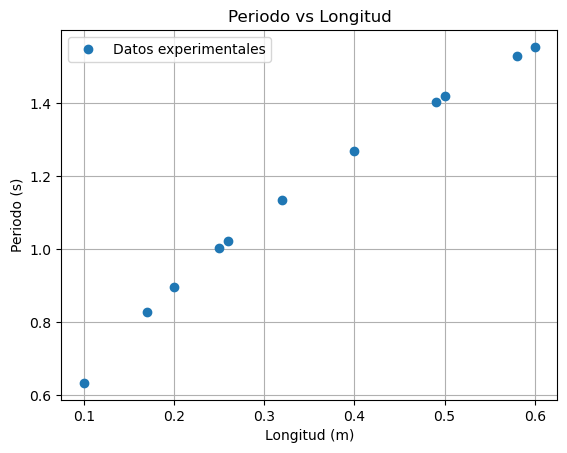

In [ ]:
# Importar las librerías necesarias
import matplotlib.pyplot as plt
import numpy as np


# Datos representados en la tabla (usando arreglos)
Longitud = np.array([0.10, 0.17, 0.20, 0.25, 0.26, 0.32, 0.40, 0.49, 0.50, 0.58, 0.60])
T_periodo = np.array([0.65, 0.79, 0.90, 1.01, 1.1, 1.2, 1.27, 1.34, 1.42, 1.50, 1.55])

#valores de T suponiendo que la gravedad es 9.81 m/s^2 y usando la formula T = 2*pi*sqrt(L/g)
T =(2*(np.pi))*(np.sqrt(Longitud/9.81))
print(f'el periodo Teórico es: \n{T}')

# Genera una gráfica
plt.plot(Longitud, T, 'o', label='Datos experimentales')
plt.title('Periodo vs Longitud')
plt.xlabel('Longitud (m)')
plt.ylabel('Periodo (s)')
plt.legend()
plt.grid()
plt.show()


datos transformados y: 
[0.4225 0.6241 0.81   1.0201 1.21   1.44   1.6129 1.7956 2.0164 2.25
 2.4025]
datos transformados x: 
[0.1  0.17 0.2  0.25 0.26 0.32 0.4  0.49 0.5  0.58 0.6 ]


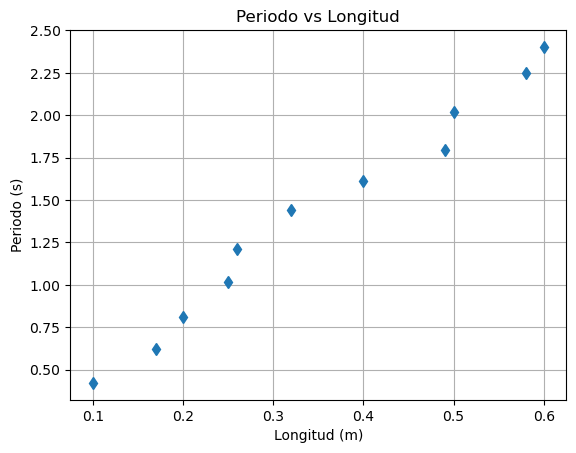

In [4]:
# Datos transformados
#------------------
Y = T_periodo**2
X = Longitud

print(f'datos transformados y: \n{Y}')
print(f'datos transformados x: \n{X}')
#------------------

# Genera una gráfica
plt.plot(X, Y,'d', label='Datos Transformaddos')
plt.xlabel('Longitud (m)')
plt.ylabel('Periodo (s)')
plt.title('Periodo vs Longitud')
plt.grid()
plt.show()


2.  Si $m=4 \pi^2 / g$ entonces $g = 4 \pi^2 / m $. Entonces , si encontramos por regresion lineal la pendiente m, podemos calcular g



In [7]:
from scipy.stats import linregress

# hallamos la ecuacion de la recta que mejor se ajusta a los datos transformados
gravedad = linregress(X, Y)
m = gravedad.slope
b = gravedad.intercept
print(f'regresion lineal es {gravedad}')
print(f'La pendiente es: {m: .6f} s^2/m')
print(f'La intersección es: {b: .6f} s^2')

# despejar la pendiente de la ecuacion de la recta para obtener la gravedad
g = (4*(np.pi)**2)/m
print(f'El valor de la gravedad es: {g: .6f} m/s^2')

regresion lineal es LinregressResult(slope=np.float64(3.8151438650306755), intercept=np.float64(0.07631756748466234), rvalue=np.float64(0.990913179241314), pvalue=np.float64(3.754985444487908e-09), stderr=np.float64(0.17261804813765208), intercept_stderr=np.float64(0.06701453751442539))
La pendiente es:  3.815144 s^2/m
La intersección es:  0.076318 s^2
El valor de la gravedad es:  10.347819 m/s^2


3. si L = 2.5, T=?


In [ ]:
#definimos la función de la recta que acepte argumentos de entrada y devuelva el valor de salida

longitud_2_5 = m* 2.5 + b

T_periodo_2_5 = np.sqrt(longitud_2_5)

T_2 =(2*(np.pi))*(np.sqrt(2.5/g))

print(f'El valor de T^2 para una longitud de 2.5 m es: {longitud_2_5: .6f} s^2')
print(f'el valor de T para una longitud de 2.5 m es: {T_periodo_2_5: .6f} s')
print(f'el valor de T utilizando el modelo con la gravedad encontrada: {T_2: .6f} s')

El valor de T^2 para una longitud de 2.5 m es:  9.614177 s^2
el valor de T para una longitud de 2.5 m es:  3.100674 s
el valor de T utilizando el modelo con la gravedad encontrada:  3.088343


4.

El polinomio interpolante de Lagrange es: 
        3         2
-233.3 x + 126.3 x - 19.07 x + 1.527


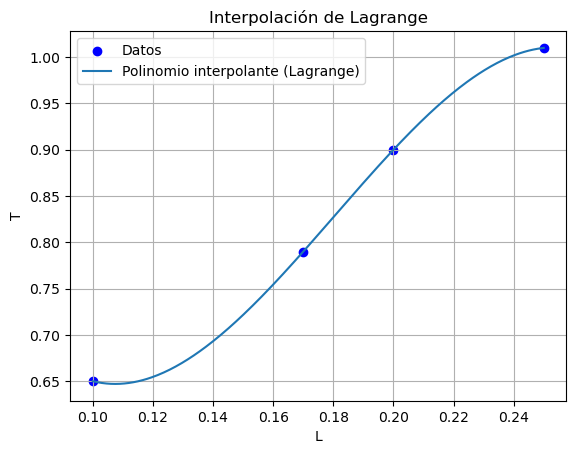

In [14]:
from scipy.interpolate import lagrange


Longitud_4  = np.array([0.10, 0.17, 0.20, 0.25])
T_periodo_4  = np.array([0.65, 0.79, 0.90, 1.01])


# Calcula el polinomio interpolante de Lagrange
P = lagrange(Longitud_4, T_periodo_4)
print(f'El polinomio interpolante de Lagrange es: \n{P}')


L_plot = np.linspace(0.10, 0.25, 300)
T_plot = P(L_plot)  # 'p' funciona como una función polinómica


plt.scatter(Longitud_4, T_periodo_4 ,label="Datos", marker='o', color='blue')
plt.plot(L_plot, T_plot, label="Polinomio interpolante (Lagrange)")
plt.title("Interpolación de Lagrange")
plt.xlabel("L")
plt.ylabel("T")
plt.legend()
plt.grid()
plt.show()


5.  L = 15 cm ,  equivale a L= 0.15 m

In [8]:
print(f"prediccion de interpolacion = {P(0.15):.6f}")

prediccion_regresion = np.sqrt(m * 0.15 + b) #si le metemos el datos de 0.15 m, Y=T^2 por eso le sacamos la raiz
print(f"prediccion de regresion utilizando la ecuación de la recta = {prediccion_regresion:.6f}")

prediccion_regresion_g_experimental = (2*(np.pi)*(np.sqrt(0.15/g)))
print(f'prediccion utilizando la ecuaion original del periodo del pendulo y la gravedad experimental = {prediccion_regresion_g_experimental:.6f}')


prediccion de interpolacion = 0.721667
prediccion de regresion utilizando la ecuación de la recta = 0.805350
prediccion utilizando la ecuaion original del periodo del pendulo y la gravedad experimental = 0.756486


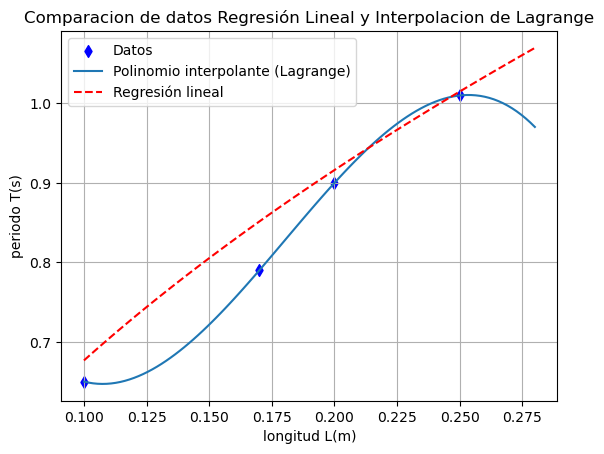

In [9]:
# Regresión lineal, Ecuacion de la recta
regresion_T4 = np.sqrt(m * L_plot + b) 

plt.scatter(Longitud_4, T_periodo_4, label="Datos", marker='d', color='blue')
plt.plot(L_plot, T_plot, label="Polinomio interpolante (Lagrange)")
plt.plot(L_plot, regresion_T4, label="Regresión lineal", linestyle ='--', color='red')
plt.title('Comparacion de datos Regresión Lineal y Interpolacion de Lagrange')
plt.xlabel("longitud L(m)")
plt.ylabel("periodo T(s)")
plt.legend()
plt.grid()
plt.show()